In [1]:
import sys
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import time
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt

print(Path.cwd())
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "splits"

sys.path.insert(0, str(ROOT))
from src.preprocess import clean_tweet, preprocess

train_df = pd.read_csv(DATA/"train.csv")
validation_df = pd.read_csv(DATA/"validation.csv")
test_df = pd.read_csv(DATA/"test.csv")

def validate(data_set):
    print(data_set.shape)
    print(data_set["label"].value_counts())
    print(data_set.isna().sum())

validate(train_df)
validate(validation_df)
validate(test_df)


/Volumes/T7 Shield/tweet-sentiment/notebooks
(200000, 3)
label
0    100000
1    100000
Name: count, dtype: int64
label    0
id       0
tweet    0
dtype: int64
(20000, 3)
label
1    10000
0    10000
Name: count, dtype: int64
label    0
id       0
tweet    0
dtype: int64
(20000, 3)
label
0    10000
1    10000
Name: count, dtype: int64
label    0
id       0
tweet    0
dtype: int64


In [2]:
for test in train_df["tweet"].sample(20, random_state=1):
    print("before:", test)
    print("after: ", clean_tweet(test))
    print()

train_df = preprocess(train_df)
validation_df = preprocess(validation_df)
test_df = preprocess(test_df)

print(train_df.shape)
print(validation_df.shape)
print(test_df.shape)
train_df.head()

before: And if you want privacy what you are you doing on twitter??? 
after:  and if you want privacy what you are you doing on twitter???

before: watching a young HOT Tom Cruise in one of my fav movies.. Top Gun... its almost over... no good 
after:  watching a young hot tom cruise in one of my fav movies.. top gun... its almost over... no good

before: http://twitpic.com/4h8g8 - @abigailcook here is the big man  he says hello!
after:  URL - USER here is the big man he says hello!

before: right i have decided, nowww im going to paint my nailsss  But first gotta watch the end of the hills &lt;333
after:  right i have decided, nowww im going to paint my nailsss but first gotta watch the end of the hills <333

before: RIP charlie the worm 
after:  rip charlie the worm

before: @arjbarker shite.... Cold and rainy.... 
after:  USER shite.... cold and rainy....

before: I'm sorry Chattanooga... You're just not my favorite city  I don't hate you by any means, but I like Nashville way bette

,label,id,tweet,clean_tweet
0,0,2323739350,Never ever!! Eat an ice cream sandwich out of ...,never ever!! eat an ice cream sandwich out of ...
1,0,2234329532,SA .. yet again,sa .. yet again
2,1,1834435622,@aussiemcflyfan aww really? maybe in a few yea...,USER aww really? maybe in a few years he will ...
3,0,2060875771,Im so tired!!! Baby sitting.,im so tired!!! baby sitting.
4,0,2189485033,"On my way to see about getting a bus, aren't c...","on my way to see about getting a bus, aren't c..."


In [3]:
y_train = train_df["label"]
y_validation = validation_df["label"]
y_test = test_df["label"]

experiments = [
    ("default", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, max_df = 100000)),
    ("ngram_range_(1,1)", TfidfVectorizer(ngram_range=(1, 1), min_df=3, sublinear_tf=True, max_df = 100000)),
    ("ngram_range_(1,3)", TfidfVectorizer(ngram_range=(1, 3), min_df=3, sublinear_tf=True, max_df = 100000)),

    ("min_df_1", TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True, max_df = 100000)),
    ("min_df_2", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_df = 100000)),
    ("min_df_5", TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True, max_df = 100000)),

    ("sublinear_tf_false", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=False, max_df = 100000)),

    ("max_df_200,000", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, max_df = 200000)),
    ("max_df_50,000", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, max_df = 50000)),

    ("token_pattern_keep ' ! ?", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, max_df=100000, token_pattern=r"[\w']+|[!?]+")),
]

results = []

for name, vectorizer in experiments:
    x_train = vectorizer.fit_transform(train_df["clean_tweet"])
    x_validation = vectorizer.transform(validation_df["clean_tweet"])

    model = LogisticRegression(max_iter=1000)
    start = time.perf_counter()
    model.fit(x_train, y_train)
    elapsed = time.perf_counter() - start

    results.append({
        "experiment": name,
        "vocabulary": x_train.shape[1],
        "train_acc": accuracy_score(y_train, model.predict(x_train)),
        "validation_acc": accuracy_score(y_validation, model.predict(x_validation)),
         "seconds": elapsed,
    })

results_df = pd.DataFrame(results)
best_row = results_df["validation_acc"].idxmax()
best_name, vectorizer = experiments[best_row]
print("best settings:", best_name)

x_train = vectorizer.fit_transform(train_df["clean_tweet"])
x_validation = vectorizer.transform(validation_df["clean_tweet"])
x_test = vectorizer.transform(test_df["clean_tweet"])

print(x_train.shape, x_validation.shape, x_test.shape)
results_df

best settings: token_pattern_keep ' ! ?
(200000, 128536) (20000, 128536) (20000, 128536)


,experiment,vocabulary,train_acc,validation_acc,seconds
0,default,121076,0.854945,0.80380,1.840454
1,"ngram_range_(1,1)",23400,0.815735,0.79080,0.549124
2,"ngram_range_(1,3)",190962,0.858720,0.80370,1.457646
3,min_df_1,834494,0.865500,0.80255,2.628309
4,min_df_2,203473,0.861795,0.80350,2.559115
5,min_df_5,69472,0.849125,0.80315,1.106153
6,sublinear_tf_false,121076,0.852270,0.80350,1.224054
7,"max_df_200,000",121076,0.854945,0.80380,1.889423
8,"max_df_50,000",121073,0.853920,0.80330,1.691643
9,token_pattern_keep ' ! ?,128536,0.852835,0.80930,0.588042


In [4]:
c_results = []

for C in [0.1, 0.5, 1, 2, 5]:
    model = LogisticRegression(solver="lbfgs", max_iter=1000, C=C)

    start = time.perf_counter()
    model.fit(x_train, y_train)
    elapsed = time.perf_counter() - start

    train_acc = accuracy_score(y_train, model.predict(x_train))
    validation_acc = accuracy_score(y_validation, model.predict(x_validation))

    c_results.append({
        "C": C,
        "train_acc": round(train_acc, 4),
        "validation_acc": round(validation_acc, 4),
        "gap": round(train_acc - validation_acc, 4),
        "seconds": round(elapsed, 1),
    })

c_results_df = pd.DataFrame(c_results)
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

results_df.to_csv(RESULTS / "baseline_settings.csv", index=False)
c_results_df.to_csv(RESULTS / "baseline_C.csv", index=False)
c_results_df

,C,train_acc,validation_acc,gap,seconds
0,0.1,0.7995,0.7838,0.0157,0.5
1,0.5,0.8345,0.8024,0.0322,0.6
2,1.0,0.8528,0.8093,0.0435,0.6
3,2.0,0.8765,0.8075,0.0690,1.8
4,5.0,0.9049,0.8050,0.0999,1.5


test accuracy:  0.8063
test F1 (macro): 0.8063
              precision    recall  f1-score   support

    negative       0.81      0.80      0.80     10000
    positive       0.80      0.81      0.81     10000

    accuracy                           0.81     20000
   macro avg       0.81      0.81      0.81     20000
weighted avg       0.81      0.81      0.81     20000

[[7976 2024]
 [1850 8150]]


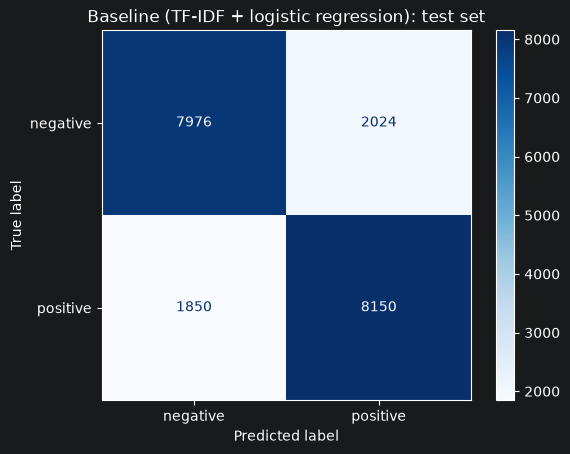

In [5]:
test_predict = model.predict(x_test)
test_acc = accuracy_score(y_test, test_predict)
test_f1 = f1_score(y_test, test_predict, average="macro")
print(f"test accuracy:  {test_acc:.4f}")
print(f"test F1 (macro): {test_f1:.4f}")
print(classification_report(y_test, test_predict, target_names=["negative", "positive"]))
cm = confusion_matrix(y_test, test_predict)
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "positive"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Baseline (TF-IDF + logistic regression): test set")
plt.savefig(ROOT / "results" / "baseline_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

Most positive words:
       word    weight
 can't wait 10.632428
  cant wait  8.102077
      happy  8.063179
 no problem  7.693216
     thanks  7.552437
    no need  6.969142
cannot wait  6.925959
    smiling  6.807453
      smile  6.785183
    not bad  6.719921
      thank  6.589411
    welcome  6.516298
       good  6.401100
    excited  6.389597
       nice  6.101460
  no school  6.029907
     hehehe  5.907725
       cute  5.785312
      proud  5.766929
       glad  5.708950

Most negative words:
         word     weight
          sad -20.043927
         sick -12.495822
         poor -12.129388
        sucks -11.498549
      missing -11.129787
         miss -10.789628
        can't -10.788802
        sadly  -9.937345
          not  -8.933407
       bummed  -8.929707
   depressing  -8.892573
          rip  -8.726731
  not looking  -8.659572
      funeral  -8.643957
           no  -8.607209
     headache  -8.527847
          ugh  -8.476830
       missed  -8.465223
unfortunately  -8.44

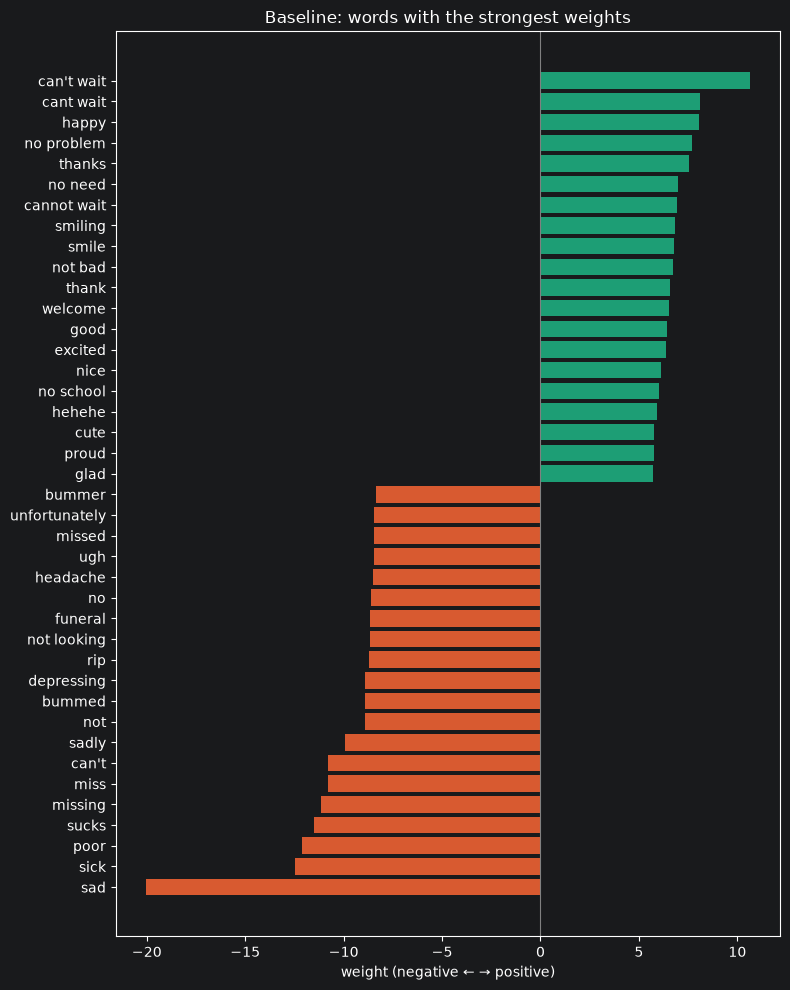

In [6]:
words = vectorizer.get_feature_names_out()
weights = model.coef_[0]
word_weights = pd.DataFrame({"word": words, "weight": weights})

top_positive = word_weights.sort_values("weight", ascending=False).head(20)
top_negative = word_weights.sort_values("weight").head(20)

print("Most positive words:")
print(top_positive.to_string(index=False))
print()
print("Most negative words:")
print(top_negative.to_string(index=False))

top = pd.concat([top_negative, top_positive.iloc[::-1]])

plt.figure(figsize=(8, 10))
colors = ["#D85A30" if w < 0 else "#1D9E75" for w in top["weight"]]
plt.barh(top["word"], top["weight"], color=colors)
plt.axvline(0, color="gray", linewidth=0.8)
plt.xlabel("weight (negative ← → positive)")
plt.title("Baseline: words with the strongest weights")
plt.tight_layout()
plt.savefig(ROOT / "results" / "baseline_top_words.png", dpi=150)
plt.show()

In [7]:
predictions = test_df[["id", "tweet", "clean_tweet", "label"]].copy()

predictions["predicted"] = test_predict
predictions["prob_positive"] = model.predict_proba(x_test)[:, 1]
predictions["correct"] = predictions["label"] == predictions["predicted"]

predictions.to_csv(ROOT / "results" / "baseline_test_predictions.csv", index=False)

print(predictions.shape)
predictions.head(10).style.format({"prob_positive": "{:.1%}"})

(20000, 7)


,id,tweet,clean_tweet,label,predicted,prob_positive,correct
0,2239206749,@disappointment http://twitpic.com/7sxp2 - You have a Friday *axe*? Our office is relatively poorly stocked,USER URL - you have a friday *axe*? our office is relatively poorly stocked,0,0,43.8%,True
1,1690787985,dropped my laptop on the bridge ov my nose can feel a lump looks bruised uhh ohhh xxx,dropped my laptop on the bridge ov my nose can feel a lump looks bruised uhh ohhh xxx,0,0,1.2%,True
2,2174779878,Goin' to bed... but not without my Kradam search for the weekend...,goin' to bed... but not without my kradam search for the weekend...,1,0,14.1%,False
3,1881939153,"Friday, payday! Or more like, bill paying day","friday, payday! or more like, bill paying day",0,1,76.0%,False
4,1996378411,"Um.. I want Brutal Legend so retardedly bad now all of a sudden. Thanks Rob Halford, Lemmy and Ozzy","um.. i want brutal legend so retardedly bad now all of a sudden. thanks rob halford, lemmy and ozzy",1,0,22.9%,False
5,1555988127,going to eat Lunch. be back in a sec.ï¿½,going to eat lunch. be back in a sec.ï¿½,1,1,95.1%,True
6,2070428044,"I'm scouting for schools, but having trouble finding degrees in science with complete online courses.","i'm scouting for schools, but having trouble finding degrees in science with complete online courses.",0,0,9.9%,True
7,2065477550,im gonna stop with my holiday memories now...just in case ur getting sick of it see thats how caring i am ;) haha,im gonna stop with my holiday memories now...just in case ur getting sick of it see thats how caring i am ;) haha,1,1,92.3%,True
8,1557307637,"@varundave anytime... and if u like punjabi khana, then come and taste rajma chawal","USER anytime... and if u like punjabi khana, then come and taste rajma chawal",1,1,99.1%,True
9,2187412601,"#WWE Drinking Game tally for the night: 21 drinks, 10 sips, 1 (big) swig. After that last match, I wish I were drunk.","wwe drinking game tally for the night: 21 drinks, 10 sips, 1 (big) swig. after that last match, i wish i were drunk.",0,0,17.0%,True


## Summary: baseline (TF-IDF + logistic regression)

### Preprocessing
Applied with `clean_tweet()` in `src/preprocess.py`, so the transformer can use exactly the same cleaning:
- Lowercased all text and remove extra spaces
- Converted HTML leftovers back to characters (`&amp;` → `&`, `&quot;` → `"`).
- Replaced URLs (`http…`, `www.…`) with `URL` and @mentions with `USER`.
- Removed the `#` from hashtags, keeping the word (`#fail` → `fail`).
- Kept punctuation such as `!!!`, `...` and emoticon text, since it carries emotion.

Not handled: stretched words (`sooooo`), typos, and garbled characters from the original file.

### Tuning (validation set: 20,000 tweets)
Default settings: `ngram_range=(1, 2), min_df=3, max_df = 100,000, sublinear_tf=True`. Each row changes one setting from the default.

| # | Change from default                        | Vocabulary | Train acc | Validation acc | Gap | Seconds |
|---|--------------------------------------------|---|---|---|---|---|
| 0 | default setting                            | 121,076 | 0.8549 | 0.8038 | 0.0511 | 1.9 |
| 1 | single words only, `ngram_range=(1, 1)`    | 23,400 | 0.8157 | 0.7908 | 0.0249 | 0.5 |
| 2 | up to 3-word phrases, `ngram_range=(1, 3)` | 190,962 | 0.8587 | 0.8037 | 0.0550 | 1.4 |
| 3 | `min_df=1`                                 | 834,494 | 0.8655 | 0.8026 | 0.0630 | 2.7 |
| 4 | `min_df=2`                                 | 203,473 | 0.8618 | 0.8035 | 0.0583 | 2.5 |
| 5 | `min_df=5`                                 | 69,472 | 0.8491 | 0.8032 | 0.0460 | 1.1 |
| 6 | `sublinear_tf=False`                       | 121,076 | 0.8523 | 0.8035 | 0.0488 | 1.2 |
| 7 | `max_df=200000`                            | 121,076 | 0.8549 | 0.8038 | 0.0511 | 1.8 |
| 8 | `max_df=50000`                             | 121,073 | 0.8539 | 0.8033 | 0.0506 | 1.7 |
| 9 | `token_pattern_keep ' ! ?"`           | 128,536 | 0.8528 | **0.8093** | 0.0435 | 0.6 |

Tuning C with the best settings: token_pattern_keep ' ! ?

### Tuning results: C (validation set: 20,000 tweets)

Vectorizer: `ngram_range=(1, 2), min_df=3, sublinear_tf=True, max_df = 100,000, token_pattern=r"[\w']+\|[!?]+"`

| C | Train acc | Validation acc | Gap | Seconds |
|---|---|---|---|---|
| 0.1 | 0.7995 | 0.7838 | 0.0157 | 0.5 |
| 0.5 | 0.8345 | 0.8024 | 0.0322 | 0.5 |
| **1** | 0.8528 | **0.8093** | 0.0435 | 0.6 |
| 2 | 0.8765 | 0.8075 | 0.0690 | 1.5 |
| 5 | 0.9049 | 0.8050 | 0.0999 | 1.5 |

**Chosen: C = 1** (highest validation accuracy).

Full results: `results/baseline_settings.csv` and `results/baseline_C.csv`.

**Observations:**
- ngram range: (1,2) gives the best accuracy (0.8038). Single words only (1,1) drops to 0.7908 (−1.30 points), the biggest change in the tuning, because word pairs capture negation and short phrases. Adding triples (1,3) gives 0.8037 (−0.01), nothing more, despite 58% more columns.
- min_df: min_df = 3 produces the best accuracy (0.8038), although the difference is minimal compared to 1 (0.8026, −0.12), 2 (0.8035, −0.03) and 5 (0.8032, −0.06). The vocabulary shrinks a lot, from 834,494 at min_df = 1 to 121,076 at min_df = 3, which remove a lot of extra unnecessary words.
- Keeping ' ! ?: Keeping `'`, `!` and `?` produces the best setting (0.8093, +0.55 points compared to 0.8038) with a smaller train–validation gap (0.0435 vs. 0.0511). It keeps words like "can't" intact and lets the model use `!!!` and `??` as emotion signals.
- C: C = 1 produced the best accuracy (0.8093); larger C allows the model to trust more words but decreases the validation accuracy: 0.8093 → 0.8075 for C = 2 and 0.8093 → 0.8050 for C = 5
- Word pairs:

### Chosen settings
- Vectorizer: `ngram_range=(1, 2), min_df=3, sublinear_tf=True, max_df = 100,000, token_pattern=r"[\w']+\|[!?]+"`
- Logistic regression: `C = 1`, `max_iter=1000`, solver `lbfgs`

### Final results (test set: 20,000 tweets, evaluated once)
| Metric | Value       |
|---|-------------|
| Accuracy | 0.8063      |
| Macro F1 | 0.8063      |
| Training time (logistic regression only) | 0.6 seconds |

Validation accuracy was 0.8063, so the test score is lower than validation (0.8093), as expected for a model tuning for validation data.

Confusion matrix: `results/baseline_confusion_matrix.png`.
Errors are roughly balanced, with a slight lean toward predicting "positive": 2,024 negative tweets were called positive, while only 1,850 positive tweets were called negative.

### What the model learned
Strongest positive words: can't wait, cant wait, happy, no problem, thanks.
Strongest negative words: sad, sick, poor, sucks, missing.
Chart: `results/baseline_top_words.png`.

- 3 out of 5 top positive words have two words, which explains why in training the setting ngram_range=(1, 2) gives the best accuracy.
- Strongest negative words mostly are adjective that described strong emotions.

### Surprises and limitations
[fill in later]


### Files
- `results/baseline_test_predictions.csv`: id, tweet, cleaned tweet, true label, predicted label, probability of positive, and whether the prediction was correct. Used in step 10.